**Multi-Hub system with locan Energy Exchange**

In [1]:
#Developer: Mo Kiani-Moghaddam (m.kiani.moghaddam@gmail.com)
#Modification: Diamantis Almpantis (diamantis.almpantis@energy.lth.se)

# Step 1: Install necessary packages
!pip install -q pyomo
!apt-get update -qq
!apt-get install -y -qq glpk-utils

# Link glpk to the system PATH so Pyomo can find it
import shutil
shutil.which("glpk")  # Verify it's installed

'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'apt-get' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
# Step 2: Import Pyomo
from pyomo.environ import *
from pyomo.opt import SolverFactory
model = ConcreteModel()

In [3]:
import pyomo.environ as pyo
print(pyo.SolverFactory('glpk').available())

True


In [4]:
#Data

# ---------------------------New Input data table for all the Hubs----------------------------------------------------

#heating demand(Dh), electrical demnad(De), cooling demand (Dc), the price of electricity (LambdaE), the price of gas (LambdaG), and solar radiation (Sr)
# Indexed as: [Dh, De, Dc, LambdaE, LambdaG, Sr]
data_dict = {
    'Hub1': {
    1:  [158.55, 141.80, 96.850, 0.38368, 0.2637, 0],
    2:  [157.68, 144.20, 91.300, 0.37193, 0.2637, 0],
    3:  [143.62, 194.60, 99.600, 0.36833, 0.2637, 0],
    4:  [147.38, 265.60, 91.750, 0.37324, 0.2637, 0],
    5:  [151.90, 261.28, 132.95, 0.37562, 0.2637, 0],
    6:  [199.90, 347.86, 115.05, 0.39992, 0.2637, 0],
    7:  [221.13, 466.92, 111.90, 0.46467, 0.3425, 0],
    8:  [218.17, 555.06, 129.05, 0.56911, 0.3425, 0.01],
    9:  [244.24, 591.28, 131.05, 0.64373, 0.3425, 0.057],
    10: [247.05, 548.40, 140.40, 0.51977, 0.3425, 0.127],
    11: [289.63, 374.62, 140.90, 0.48616, 0.3425, 0.163],
    12: [266.95, 352.50, 157.30, 0.44426, 0.3425, 0.201],
    13: [268.62, 311.40, 141.70, 0.40106, 0.3425, 0.251],
    14: [291.63, 376.90, 137.40, 0.38371, 0.3425, 0.196],
    15: [289.23, 377.30, 154.45, 0.38126, 0.3425, 0.052],
    16: [244.34, 412.20, 127.05, 0.42016, 0.3425, 0],
    17: [211.51, 433.08, 129.80, 0.43563, 0.3425, 0],
    18: [201.04, 558.64, 116.20, 0.44226, 0.3425, 0],
    19: [203.36, 589.48, 111.70, 0.47434, 0.2637, 0],
    20: [215.93, 552.70, 128.55, 0.56400, 0.2637, 0],
    21: [221.64, 426.90, 92.100, 0.50952, 0.2637, 0],
    22: [185.81, 336.48, 96.005, 0.45427, 0.2637, 0],
    23: [153.91, 241.84, 97.450, 0.43735, 0.2637, 0],
    24: [154.14, 126.80, 90.050, 0.39004, 0.2637, 0]
},
    'Hub2': {},
    'Hub3': {}
}

# Populate data for Hub2 and Hub3 based on Hub1's data
for t in data_dict['Hub1']:
    data_dict['Hub2'][t] = [0.8 * data_dict['Hub1'][t][0], 0.6 * data_dict['Hub1'][t][1], 1.2 * data_dict['Hub1'][t][2]] + data_dict['Hub1'][t][3:]
    data_dict['Hub3'][t] = [0.5 * data_dict['Hub1'][t][0], 0.8 * data_dict['Hub1'][t][1], 0.9 * data_dict['Hub1'][t][2]] + data_dict['Hub1'][t][3:]

# Parameters
# EES (Electrical Energy Storage)
EESinitial = 15
EESmin = 10
EESmax = 100
PchEESmin = 0
PchEESmax = 20
PdisEESmin = 0
PdisEESmax = 20
EtachEES = 0.98
EtadisEES = 0.98
SelfdisEES = 0.005

# TES (Thermal Energy Storage)
TESinitial = 15
TESmin = 10
TESmax = 80
TchTESmin = 0
TchTESmax = 20
TdisTESmin = 0
TdisTESmax = 20
EtachTES = 0.95
EtadisTES = 0.95
SelfdisTES = 0.008

# Transformer
EtaTr = 0.98

# CHP (Combined Heat and Power)
EtaCHP_GE = 0.45
EtaCHP_GH = 0.35
CACHPmax = 600

# GF (Gas Furnace)
CAGFmax = 300
EtaGF = 0.8

# EHP (Electric Heat Pump)
HEHPmin = 0
HEHPmax = 150
CEHPmin = 0
CEHPmax = 150
COP = 2.5

# CH (Chiller)
EtaCB = 1.2
CCBmin = 0
CCBmax = 140

# PV (Photovoltaic)
SPVe = 200
EtaPVe = 0.35
PVePmin = 0
PVePmax = 100

# Emission factors
PhiEl = 0.968
PhiGa = 0.22
OmeCO2 = 0.0385

In [5]:
# Define the model
model = ConcreteModel()

#-------New set for the hubs-----------------
HUBS = ['Hub1', 'Hub2', 'Hub3']
model.hubs = Set(initialize=HUBS)
model.t = RangeSet(1, 24)

# Variables
# Free variables
model.cost = Var()
model.OperationCost = Var()
model.EmissionCost = Var()

# Positive variables
model.E = Var(model.hubs,model.t, domain=NonNegativeReals)
model.G = Var(model.hubs,model.t, domain=NonNegativeReals)
model.PPV = Var(model.hubs,model.t, domain=NonNegativeReals)
model.PchEES = Var(model.hubs,model.t, domain=NonNegativeReals)
model.PdisEES = Var(model.hubs,model.t, domain=NonNegativeReals)
model.EES = Var(model.hubs,model.t, domain=NonNegativeReals)
model.EinEES = Var(model.hubs,model.t, domain=NonNegativeReals)
model.TchTES = Var(model.hubs,model.t, domain=NonNegativeReals)
model.TdisTES = Var(model.hubs,model.t, domain=NonNegativeReals)
model.TES = Var(model.hubs,model.t, domain=NonNegativeReals)
model.EinTr = Var(model.hubs,model.t, domain=NonNegativeReals)
model.ETr = Var(model.hubs,model.t, domain=NonNegativeReals)
model.GinCHP = Var(model.hubs,model.t, domain=NonNegativeReals)
model.ECHP = Var(model.hubs,model.t, domain=NonNegativeReals)
model.HCHP = Var(model.hubs,model.t, domain=NonNegativeReals)
model.GinGF = Var(model.hubs,model.t, domain=NonNegativeReals)
model.HGF = Var(model.hubs,model.t, domain=NonNegativeReals)
model.EinEHP = Var(model.hubs,model.t, domain=NonNegativeReals)
model.HEHP = Var(model.hubs,model.t, domain=NonNegativeReals)
model.CEHP = Var(model.hubs,model.t, domain=NonNegativeReals)
model.HinCB = Var(model.hubs,model.t, domain=NonNegativeReals)
model.CCB = Var(model.hubs,model.t, domain=NonNegativeReals)

# Binary variables
model.IdisEES = Var(model.hubs,model.t, domain=Binary)
model.IchEES = Var(model.hubs,model.t, domain=Binary)
model.IdisTES = Var(model.hubs,model.t, domain=Binary)
model.IchTES = Var(model.hubs,model.t, domain=Binary)
model.IcEHP = Var(model.hubs,model.t, domain=Binary)
model.IhEHP = Var(model.hubs,model.t, domain=Binary)

#_________New variables for the local energy exchange_________________________________________________________________________
# Exchange between hubs variables
model.E_ex = Var(model.hubs, model.hubs, model.t, domain=NonNegativeReals)
model.H_ex = Var(model.hubs, model.hubs, model.t, domain=NonNegativeReals)

MaxEx = 50/2 #Example: Max electrical exchange per timestep
def exchange_limit_rule(model, h1, h2, t):
    return model.E_ex[h1, h2, t] <= MaxEx
model.exchange_limit = Constraint(model.hubs, model.hubs, model.t, rule=exchange_limit_rule)

def no_self_transfer(model, h, t):
    return model.E_ex[h, h, t] == 0
model.no_self = Constraint(model.hubs, model.t, rule=no_self_transfer)

MaxHex = 50/2  # Example: Max heat exchange per timestep
def heat_exchange_limit_rule(model, h1, h2, t):
    return model.H_ex[h1, h2, t] <= MaxHex
model.heat_exchange_limit = Constraint(model.hubs, model.hubs, model.t, rule=heat_exchange_limit_rule)

def no_self_heat_transfer(model, h, t):
    return model.H_ex[h, h, t] == 0
model.no_self_heat = Constraint(model.hubs, model.t, rule=no_self_heat_transfer)

#________Instead of time we have and the model of hubs network__________________________________________________________________________

# Objective function constraints_____________________________________________________________
def operation_cost_rule(model):
    return model.OperationCost == sum(sum(data_dict[h][t][3] * model.E[h,t] + data_dict[h][t][4] * model.G[h,t] for t in model.t) for h in model.hubs)
model.Eq1 = Constraint(rule=operation_cost_rule)

def emission_cost_rule(model):
    return model.EmissionCost == OmeCO2 * sum(sum(PhiEl * model.E[h,t] + PhiGa * model.G[h,t] for t in model.t) for h in model.hubs)
model.Eq2 = Constraint(rule=emission_cost_rule)

def total_cost_rule(model):
    return model.cost == model.OperationCost
model.Eq3 = Constraint(rule=total_cost_rule)

# Objective
model.obj = Objective(expr=model.cost, sense=minimize)

#__________________________________________________________________________________________________
# EES constraints
def pch_ees_min_rule(model, h,t):
    return model.PchEES[h,t] >= PchEESmin * model.IchEES[h,t]
model.Eq4 = Constraint(model.hubs,model.t, rule=pch_ees_min_rule)

def pch_ees_max_rule(model,h,t):
    return model.PchEES[h,t] <= PchEESmax * model.IchEES[h,t]
model.Eq5 = Constraint(model.hubs,model.t, rule=pch_ees_max_rule)

def pdis_ees_min_rule(model, h,t):
    return model.PdisEES[h,t] >= PdisEESmin * model.IdisEES[h,t]
model.Eq6 = Constraint(model.hubs,model.t, rule=pdis_ees_min_rule)

def pdis_ees_max_rule(model, h,t):
    return model.PdisEES[h,t] <= PdisEESmax * model.IdisEES[h,t]
model.Eq7 = Constraint(model.hubs,model.t, rule=pdis_ees_max_rule)

def ees_binary_rule(model, h,t):
    return model.IchEES[h,t] + model.IdisEES[h,t] <= 1
model.Eq8 = Constraint(model.hubs,model.t, rule=ees_binary_rule)

def ees_balance_t1_rule(model, h):
    return model.EES[h, 1] == EESinitial + (model.PchEES[h, 1] * EtachEES) - (model.PdisEES[h, 1] / EtadisEES)
model.Eq91 = Constraint(model.hubs, rule=ees_balance_t1_rule)

def ees_balance_rule(model, h,t):
    if t >= 2 and t <= 24:
        return model.EES[h,t] == model.EES[h,t-1] + (model.PchEES[h,t] * EtachEES) - (model.PdisEES[h,t] / EtadisEES) - (SelfdisEES * model.EES[h,t-1])
    else:
        return Constraint.Skip
model.Eq92 = Constraint(model.hubs,model.t, rule=ees_balance_rule)

def ees_final_rule(model, h):
    return model.EES[h, 24] >= EESinitial
model.Eq93 = Constraint(model.hubs, rule=ees_final_rule)

def ees_min_rule(model, h, t):
    return model.EES[h,t] >= EESmin
model.Eq10 = Constraint(model.hubs,model.t, rule=ees_min_rule)

def ees_max_rule(model, h,t):
    return model.EES[h,t] <= EESmax
model.Eq11 = Constraint(model.hubs,model.t, rule=ees_max_rule)

#_______________________________________________________________________________________________________________
# TES constraints
def tch_tes_min_rule(model, h,t):
    return model.TchTES[h,t] >= TchTESmin * model.IchTES[h,t]
model.Eq12 = Constraint(model.hubs,model.t, rule=tch_tes_min_rule)

def tch_tes_max_rule(model, h,t):
    return model.TchTES[h,t] <= TchTESmax * model.IchTES[h,t]
model.Eq13 = Constraint(model.hubs,model.t, rule=tch_tes_max_rule)

def tdis_tes_min_rule(model, h,t):
    return model.TdisTES[h,t] >= TdisTESmin * model.IdisTES[h,t]
model.Eq14 = Constraint(model.hubs,model.t, rule=tdis_tes_min_rule)

def tdis_tes_max_rule(model,h, t):
    return model.TdisTES[h,t] <= TdisTESmax * model.IdisTES[h,t]
model.Eq15 = Constraint(model.hubs,model.t, rule=tdis_tes_max_rule)

def tes_binary_rule(model,h, t):
    return model.IchTES[h,t] + model.IdisTES[h,t] <= 1
model.Eq16 = Constraint(model.hubs,model.t, rule=tes_binary_rule)

def tes_balance_t1_rule(model, h):
    return model.TES[h, 1] == TESinitial + (model.TchTES[h, 1] * EtachTES) - (model.TdisTES[h, 1] / EtadisTES)
model.Eq171 = Constraint(model.hubs, rule=tes_balance_t1_rule)

def tes_balance_rule(model,h, t):
    if t >= 2 and t <= 24:
        return model.TES[h,t] == model.TES[h,t-1] + (model.TchTES[h,t] * EtachTES) - (model.TdisTES[h,t] / EtadisTES) - (SelfdisTES * model.TES[h,t-1])
    else:
        return Constraint.Skip
model.Eq172 = Constraint(model.hubs,model.t, rule=tes_balance_rule)

def tes_final_rule(model, h):
    return model.TES[h, 24] >= TESinitial
model.Eq173 = Constraint(model.hubs, rule=tes_final_rule)

def tes_min_rule(model, h,t):
    return model.TES[h,t] >= TESmin
model.Eq18 = Constraint(model.hubs,model.t, rule=tes_min_rule)

def tes_max_rule(model, h,t):
    return model.TES[h,t] <= TESmax
model.Eq19 = Constraint(model.hubs,model.t, rule=tes_max_rule)

#________________________________________________________________________________________________________________
# Transformer constraint
def transformer_rule(model,h, t):
    return model.ETr[h,t] == EtaTr * model.EinTr[h,t]
model.Eq20 = Constraint(model.hubs,model.t, rule=transformer_rule)

#_______________________________________________________________________________________________________________
# CHP constraints
def chp_elec_rule(model, h, t):
    return model.ECHP[h,t] == EtaCHP_GE * model.GinCHP[h,t]
model.Eq21 = Constraint(model.hubs,model.t, rule=chp_elec_rule)

def chp_heat_rule(model,h, t):
    return model.HCHP[h,t] == EtaCHP_GH * model.GinCHP[h,t]
model.Eq22 = Constraint(model.hubs,model.t, rule=chp_heat_rule)

def chp_capacity_rule(model,h, t):
    return model.GinCHP[h,t] <= CACHPmax
model.Eq23 = Constraint(model.hubs,model.t, rule=chp_capacity_rule)

#__________________________________________________________________________________________________________________
# GF constraints
def gf_heat_rule(model, h,t):
    return model.HGF[h,t] == EtaGF * model.GinGF[h,t]
model.Eq24 = Constraint(model.hubs,model.t, rule=gf_heat_rule)

def gf_capacity_rule(model, h,t):
    return model.GinGF[h,t] <= CAGFmax
model.Eq25 = Constraint(model.hubs,model.t, rule=gf_capacity_rule)

#_____________________________________________________________________________________________________________________
# EHP constraints
def ehp_cop_rule(model,h, t):
    return model.HEHP[h,t] + model.CEHP[h,t] == model.EinEHP[h,t] * COP
model.Eq26 = Constraint(model.hubs,model.t, rule=ehp_cop_rule)

def ehp_heat_min_rule(model,h, t):
    return model.HEHP[h,t] >= HEHPmin * model.IhEHP[h,t]
model.Eq27 = Constraint(model.hubs,model.t, rule=ehp_heat_min_rule)

def ehp_heat_max_rule(model,h, t):
    return model.HEHP[h,t] <= HEHPmax * model.IhEHP[h,t]
model.Eq28 = Constraint(model.hubs,model.t, rule=ehp_heat_max_rule)

def ehp_cool_min_rule(model,h, t):
    return model.CEHP[h,t] >= CEHPmin * model.IcEHP[h,t]
model.Eq29 = Constraint(model.hubs,model.t, rule=ehp_cool_min_rule)

def ehp_cool_max_rule(model,h, t):
    return model.CEHP[h,t] <= CEHPmax * model.IcEHP[h,t]
model.Eq30 = Constraint(model.hubs,model.t, rule=ehp_cool_max_rule)

def ehp_binary_rule(model, h,t):
    return model.IcEHP[h,t] + model.IhEHP[h,t] <= 1
model.Eq31 = Constraint(model.hubs,model.t, rule=ehp_binary_rule)

#__________________________________________________________________________________________________________________________
# CB (Chiller) constraints
def cb_rule(model,h, t):
    return model.CCB[h,t] == EtaCB * model.HinCB[h,t]
model.Eq32 = Constraint(model.hubs,model.t, rule=cb_rule)

def cb_min_rule(model,h, t):
    return model.CCB[h,t] >= CCBmin
model.Eq33 = Constraint(model.hubs,model.t, rule=cb_min_rule)

def cb_max_rule(model,h,t):
    return model.CCB[h,t] <= CCBmax
model.Eq34 = Constraint(model.hubs,model.t, rule=cb_max_rule)

#____________________________________________________________________________________________________________________________
# PV constraints
def pv_generation_rule(model,h, t):
    return model.PPV[h,t] == SPVe * EtaPVe * data_dict[h][t][5]
model.Eq35 = Constraint(model.hubs,model.t, rule=pv_generation_rule)

def pv_min_rule(model, h,t):
    return model.PPV[h,t] >= PVePmin
model.Eq36 = Constraint(model.hubs,model.t, rule=pv_min_rule)

def pv_max_rule(model,h, t):
    return model.PPV[h,t] <= PVePmax
model.Eq37 = Constraint(model.hubs,model.t, rule=pv_max_rule)

#________________________________________________________________________________________________________________________________
# Energy balance equations
def elec_input_balance_rule(model, h,t):
    return model.E[h,t] == model.EinEES[h,t] + model.EinTr[h,t]
model.Eq38 = Constraint(model.hubs,model.t, rule=elec_input_balance_rule)

def ees_input_rule(model,h, t):
    return model.EinEES[h,t] == model.PchEES[h,t]
model.Eq39 = Constraint(model.hubs,model.t, rule=ees_input_rule)

#_________________________________________________________________________________________________________________________________
def gas_balance_rule(model,h, t):
    return model.G[h,t] == model.GinCHP[h,t] + model.GinGF[h,t]
model.Eq40 = Constraint(model.hubs,model.t, rule=gas_balance_rule)

#______New Electrical Balance Constraint including the local electrical exchange____________________________________________________

def elec_balance_rule(model, h, t):
    inflow = model.E[h, t] + model.PdisEES[h, t] + model.ECHP[h, t] + model.PPV[h, t] + \
             sum(model.E_ex[other, h, t] for other in model.hubs if other != h)

    outflow = model.EinEES[h, t] + model.EinEHP[h, t] + data_dict[h][t][1] + \
              sum(model.E_ex[h, other, t] for other in model.hubs if other != h)

    return inflow == outflow
model.Eq41 = Constraint(model.hubs, model.t, rule=elec_balance_rule)


#______New Heating Balance Constraint including the local heating exchange____________________________________________

def heat_demand_balance_rule(model, h, t):
    inflow = model.HCHP[h, t] + model.HGF[h, t] + model.HEHP[h, t] + model.TdisTES[h, t] + \
             sum(model.H_ex[other, h, t] for other in model.hubs if other != h)

    outflow = model.HinCB[h, t] + model.TchTES[h, t] + data_dict[h][t][0] + \
              sum(model.H_ex[h, other, t] for other in model.hubs if other != h)

    return inflow == outflow
model.Eq42 = Constraint(model.hubs, model.t, rule=heat_demand_balance_rule)


#______________The same cooling constraint but in all the hubs___________________________________________________________
def cool_demand_balance_rule(model,h, t):
    return model.CCB[h,t] + model.CEHP[h,t] == data_dict[h][t][2]
model.Eq43 = Constraint(model.hubs,model.t, rule=cool_demand_balance_rule)

In [6]:
# Solve the model
solver = SolverFactory('glpk')
result = solver.solve(model)

# Load the results back into the model
model.solutions.load_from(result)

In [7]:
# Display results
# Check if solution is optimal
if result.solver.termination_condition == TerminationCondition.optimal:
    print("\n" + "="*50)
    print("OPTIMAL SOLUTION FOUND")
    print("="*50)

    print(f"Operation Cost: {value(model.OperationCost):.2f}")
    print(f"Emission Cost: {value(model.EmissionCost):.2f}")
    print(f"Onjective (Minimize Operational Cost): {value(model.cost):.2f}")
else:
    print(f"Solver Status: {result.solver.status}")
    print(f"Termination Condition: {result.solver.termination_condition}")


OPTIMAL SOLUTION FOUND
Operation Cost: 14416.58
Emission Cost: 769.93
Onjective (Minimize Operational Cost): 14416.58


In [8]:
results_data = {}
for h in model.hubs:
  for t in model.t:
    results_data[h,t] = [
        value(model.E[h,t]),
        value(model.EinTr[h,t]),
        value(model.EinEES[h,t]),
        value(model.PPV[h,t]),
        value(model.ETr[h,t]),
        value(model.PdisEES[h,t]),
        value(model.PchEES[h,t]),
        value(model.EES[h,t]),
        value(model.ECHP[h,t]),
        value(model.EinEHP[h,t]),
        #________________________
        value(model.G[h,t]),
        value(model.GinCHP[h,t]),
        value(model.GinGF[h,t]),
        value(model.HinCB[h,t]),
        value(model.HGF[h,t]),
        value(model.HEHP[h,t]),
        value(model.HCHP[h,t]),
        value(model.TchTES[h,t]),
        value(model.TdisTES[h,t]),
        value(model.TES[h,t]),
        value(model.CEHP[h,t]),
        value(model.CCB[h,t]),

    ]

In [9]:
import pandas as pd

column_names = [
    'Electricity Purchase','EinTr','EinEES','PV Generation','ETr','PdisEES','PchEES','EES State of Charge','ECHP','EinEHP',
    'Gas Purchase','GinCHP','GinGF','HinCB','HGF','HEHP','HCHP','TchTES','TdisTES','TES State of Charge','CEHP','CCB'

]

# Reformat results_data into a list of records with hub and time as separate columns
formatted_results_data = []
for (hub, time), values in results_data.items():
    formatted_results_data.append([hub, time] + values)

# Create a DataFrame with explicit columns for 'Hub' and 'Time Step'
df_results = pd.DataFrame(formatted_results_data, columns=['Hub', 'Time Step'] + column_names)

# Set the MultiIndex
df_results = df_results.set_index(['Hub', 'Time Step'])

# Debugging: Print the MultiIndex levels and their unique values after setting the index
print("DataFrame MultiIndex Levels:")
print(df_results.index.levels)
print("\nUnique values in the first level of the index (after setting index):")
print(df_results.index.get_level_values(0).unique())

# Save the DataFrame to an Excel file with separate sheets for each hub
excel_file_name = 'optimization_results_Case3.xlsx'

with pd.ExcelWriter(excel_file_name) as writer:
    for h in model.hubs:
        # Filter the DataFrame for the current hub using .loc with the first level of the MultiIndex
        try:
            df_hub = df_results.loc[h]
        except KeyError as e:
            print(f"KeyError when trying to filter for hub {h}: {e}")
            continue # Skip this hub if the key is not found


        if not df_hub.empty:
             # Write the hub's data to a separate sheet named after the hub
            df_hub.to_excel(writer, sheet_name=str(h), index_label='Time Step')
        else:
            print(f"No data for hub {h}. Skipping sheet creation.")


print(f"\nResults saving process completed for {excel_file_name}.")

DataFrame MultiIndex Levels:
[['Hub1', 'Hub2', 'Hub3'], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]]

Unique values in the first level of the index (after setting index):
Index(['Hub1', 'Hub2', 'Hub3'], dtype='object', name='Hub')

Results saving process completed for optimization_results_Case3.xlsx.


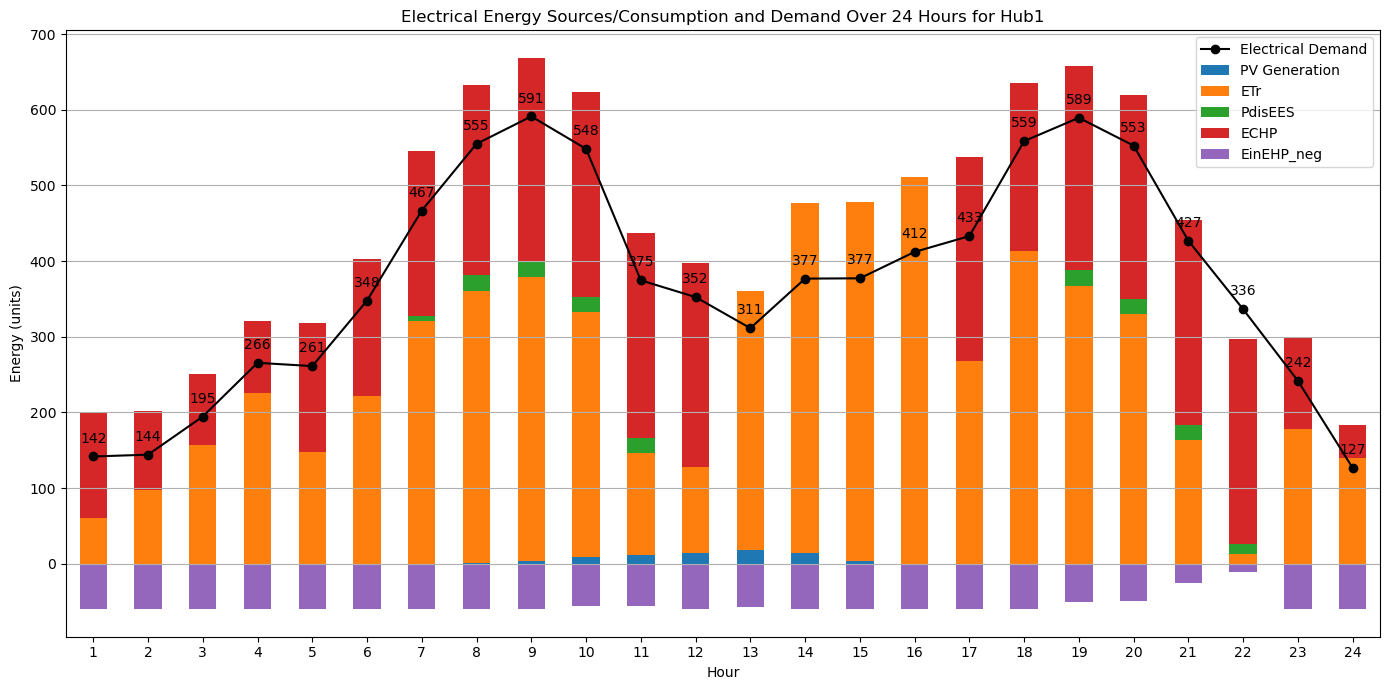

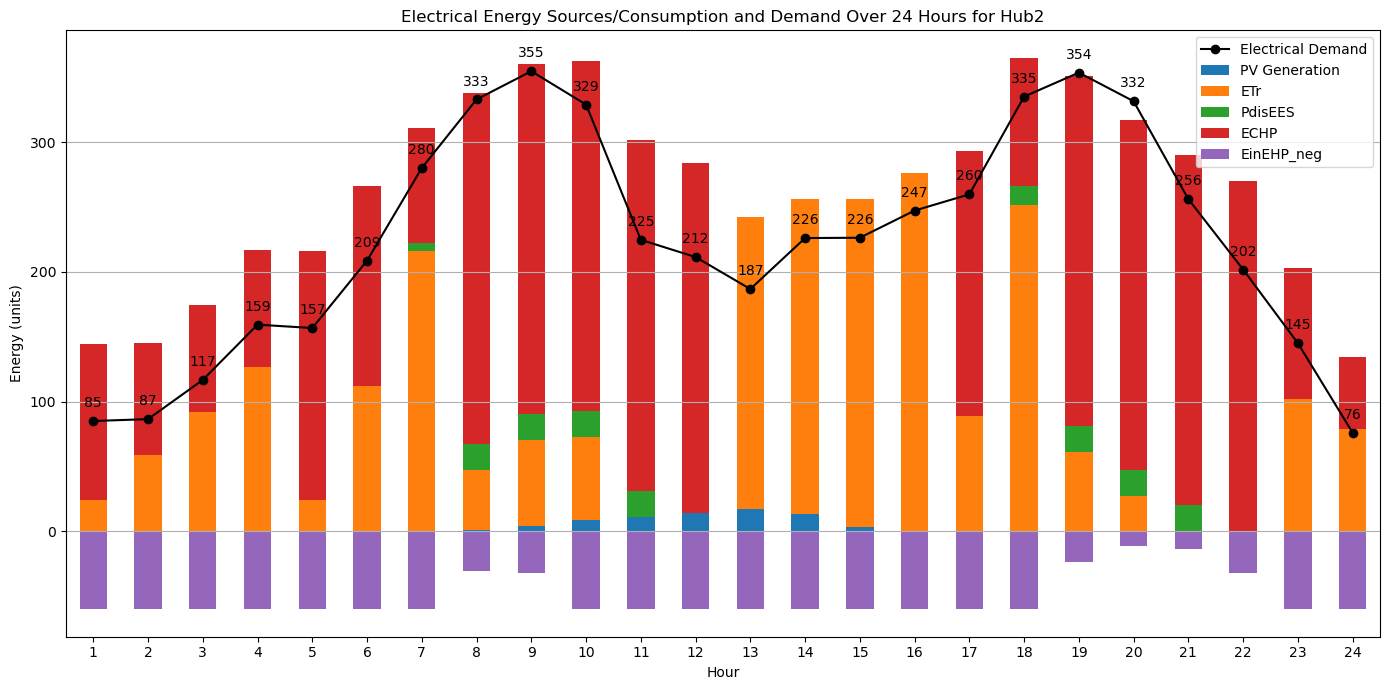

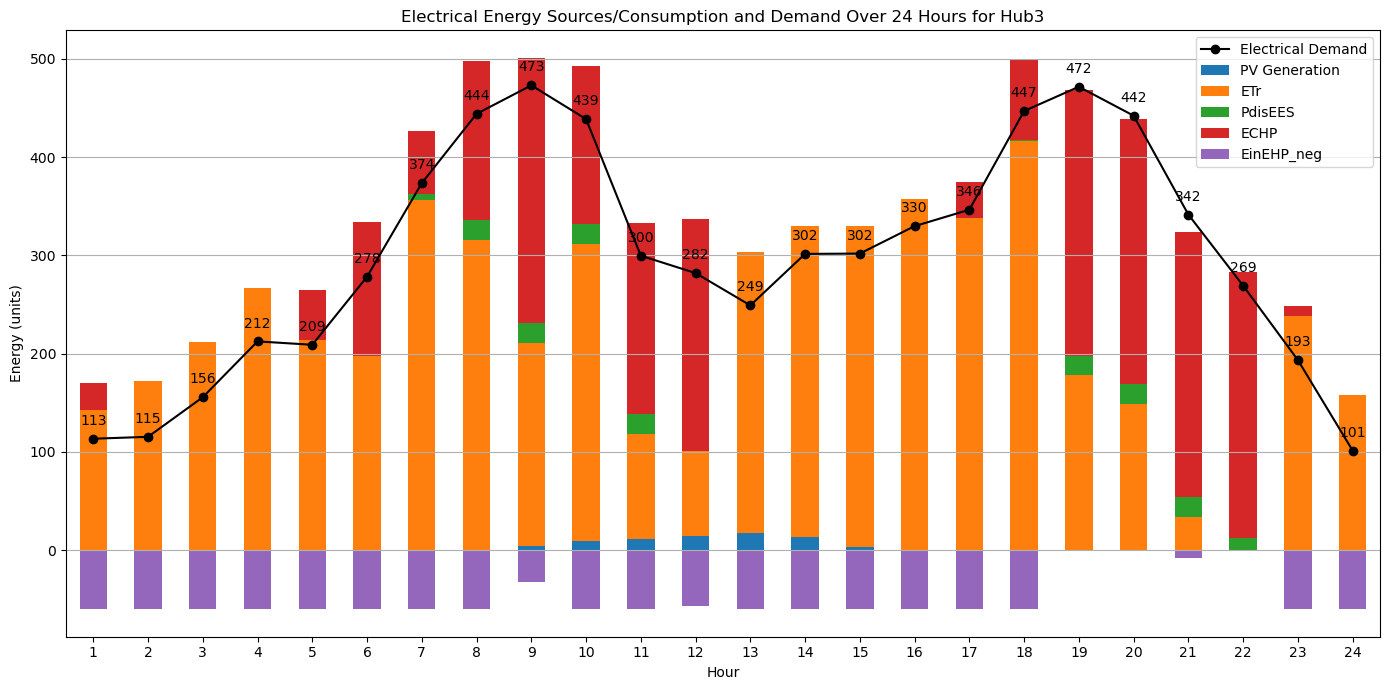

In [10]:
import matplotlib.pyplot as plt
import pandas as pd


# Create a new column with negative values for EinEHP to represent consumption
df_results['EinEHP_neg'] = -df_results['EinEHP']

# Select the relevant columns for the stacked bar plot, including the negative EinEHP
plot_columns = ['PV Generation', 'ETr', 'PdisEES', 'ECHP', 'EinEHP_neg']

for h in model.hubs:
    # Filter data for the current hub
    df_hub = df_results.loc[h]

    # Create the stacked bar plot for the current hub
    fig, ax1 = plt.subplots(figsize=(14, 7))
    df_hub[plot_columns].plot(kind='bar', stacked=True, ax=ax1)

    ax1.set_xlabel("Hour")
    ax1.set_ylabel("Energy (units)")
    ax1.set_title(f"Electrical Energy Sources/Consumption and Demand Over 24 Hours for {h}")
    ax1.tick_params(axis='x', rotation=0) # Keep x-axis labels horizontal
    ax1.legend(title="Source/Consumption", loc='upper left')
    ax1.grid(axis='y') # Add a horizontal grid for better readability

    # Add the electrical demand line on the primary y-axis
    electrical_demand = [data_dict[h][t][1] for t in model.t]
    demand_line, = ax1.plot(df_hub.index.get_level_values('Time Step') - 1, electrical_demand, color='black', marker='o', linestyle='-', label='Electrical Demand') # plot_data.index-1 to align with 0-based indexing of plot

    # Combine legends
    handles, labels = ax1.get_legend_handles_labels()
    ax1.legend(handles=handles, loc='upper right')


    # Add annotations for the electrical demand line
    for i, txt in enumerate(electrical_demand):
        ax1.annotate(f'{txt:.0f}', (df_hub.index.get_level_values('Time Step')[i] - 1, electrical_demand[i]), textcoords="offset points", xytext=(0,10), ha='center')


    plt.tight_layout() # Adjust layout to prevent labels overlapping
    plt.show()

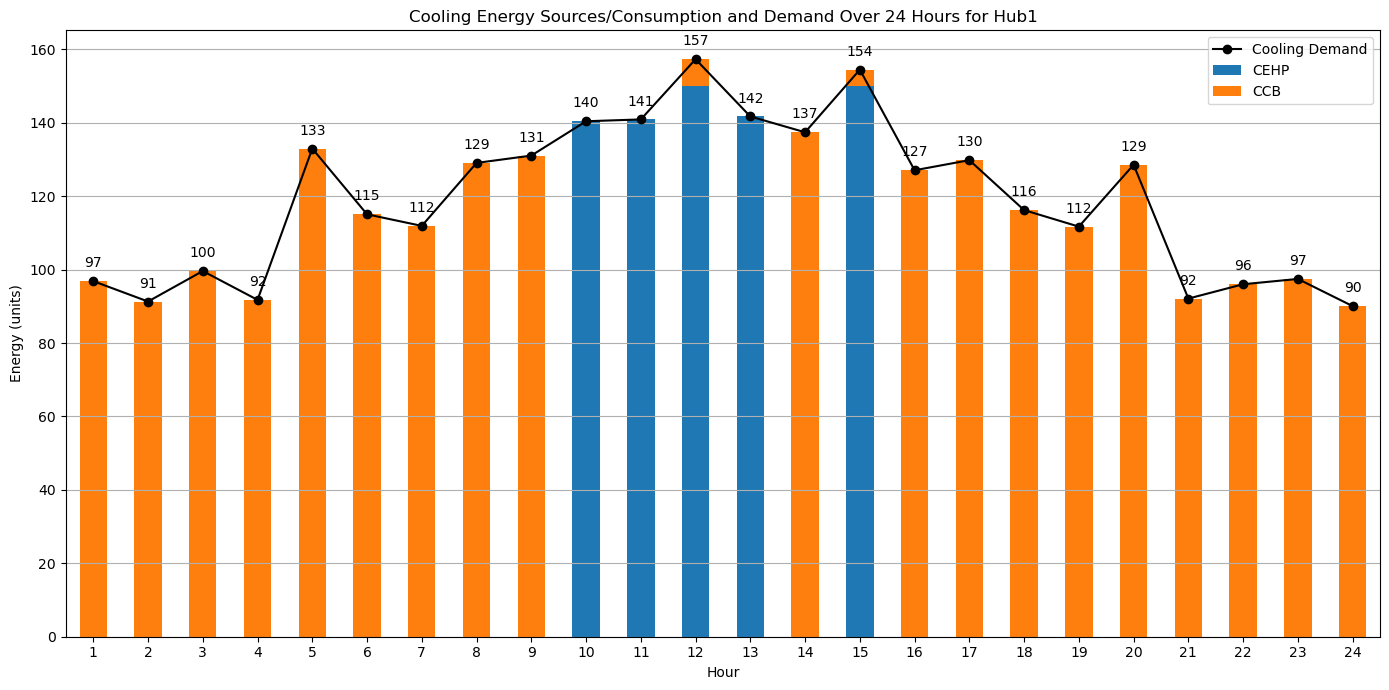

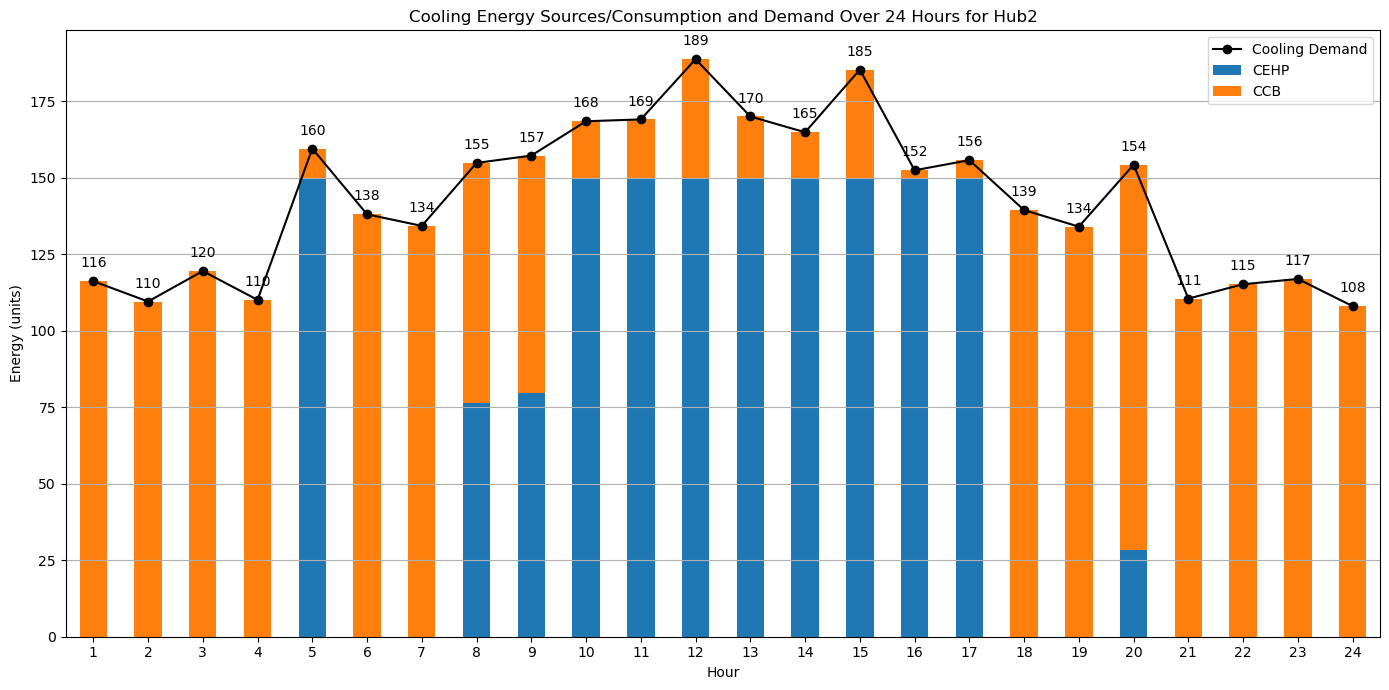

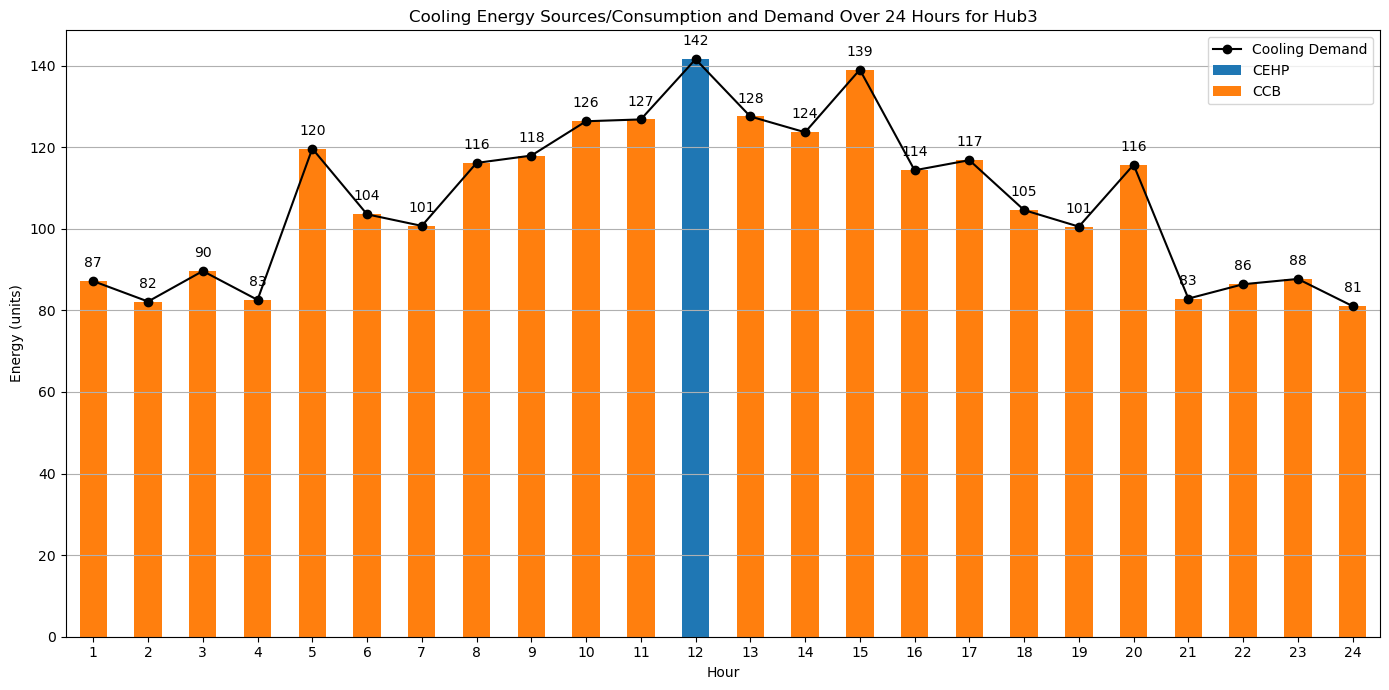

In [11]:
import matplotlib.pyplot as plt
import pandas as pd


# Select the relevant columns for the stacked bar plot, including the negative EinEHP
plot_columns = ['CEHP','CCB']

for h in model.hubs:
    # Filter data for the current hub
    df_hub = df_results.loc[h]

    # Create the stacked bar plot for the current hub
    fig, ax1 = plt.subplots(figsize=(14, 7))
    df_hub[plot_columns].plot(kind='bar', stacked=True, ax=ax1)

    ax1.set_xlabel("Hour")
    ax1.set_ylabel("Energy (units)")
    ax1.set_title(f"Cooling Energy Sources/Consumption and Demand Over 24 Hours for {h}")
    ax1.tick_params(axis='x', rotation=0) # Keep x-axis labels horizontal
    ax1.legend(title="Source/Consumption", loc='upper left')
    ax1.grid(axis='y') # Add a horizontal grid for better readability

    # Add the cooling demand line on the primary y-axis
    cooling_demand = [data_dict[h][t][2] for t in model.t] # Extract cooling demand from data_dict
    # Plot the demand line against the index positions (0 to 23) to align with the bars
    demand_line, = ax1.plot(range(len(cooling_demand)), cooling_demand, color='black', marker='o', linestyle='-', label='Cooling Demand')
    # Combine legends
    handles, labels = ax1.get_legend_handles_labels()
    ax1.legend(handles=handles, loc='upper right') # Add the legend for the cooling demand line

    # Add annotations for the cooling demand line
    for i, txt in enumerate(cooling_demand):
        ax1.annotate(f'{txt:.0f}', (i, cooling_demand[i]), textcoords="offset points", xytext=(0,10), ha='center')

    plt.tight_layout() # Adjust layout to prevent labels overlapping
    plt.show()

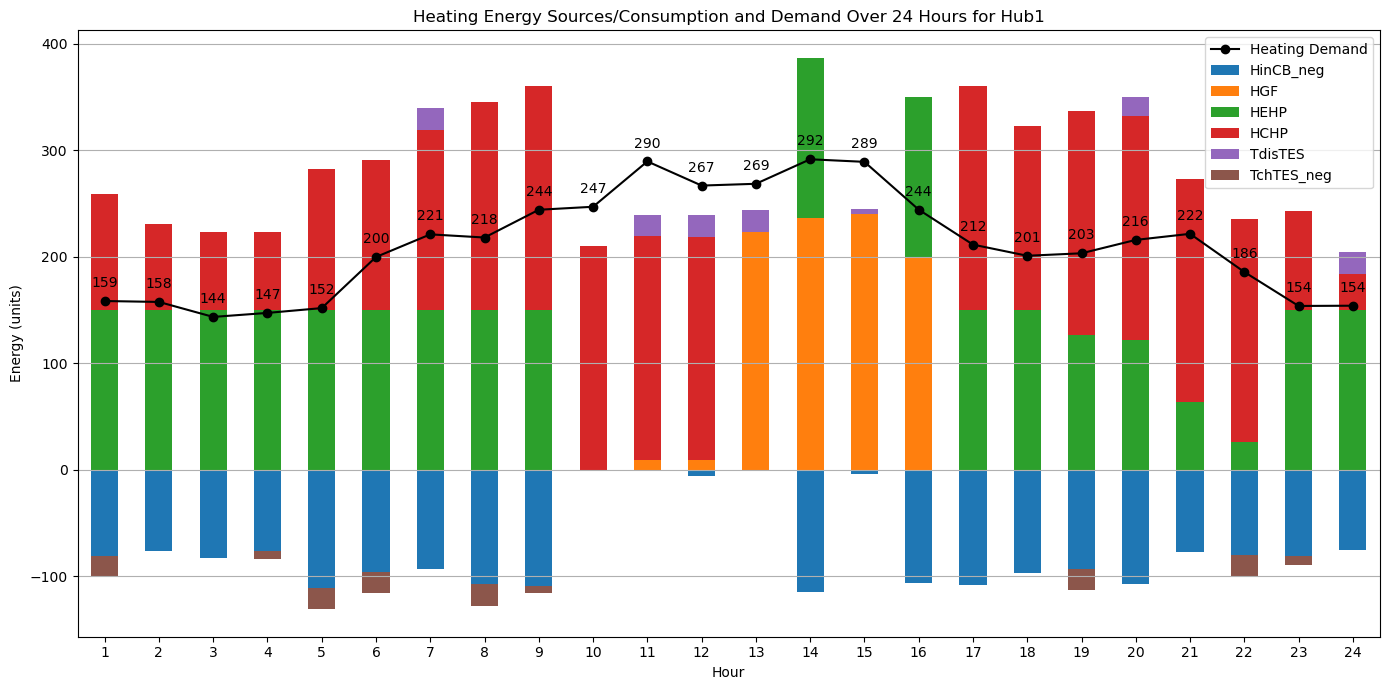

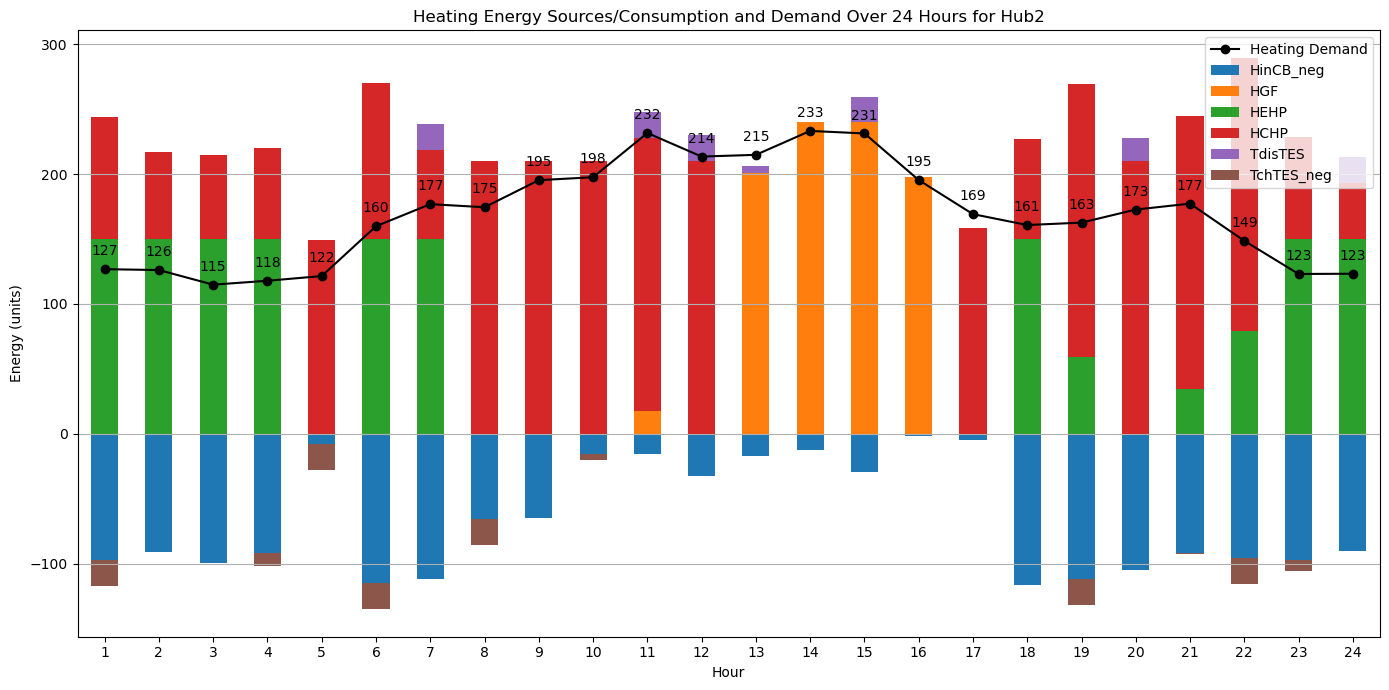

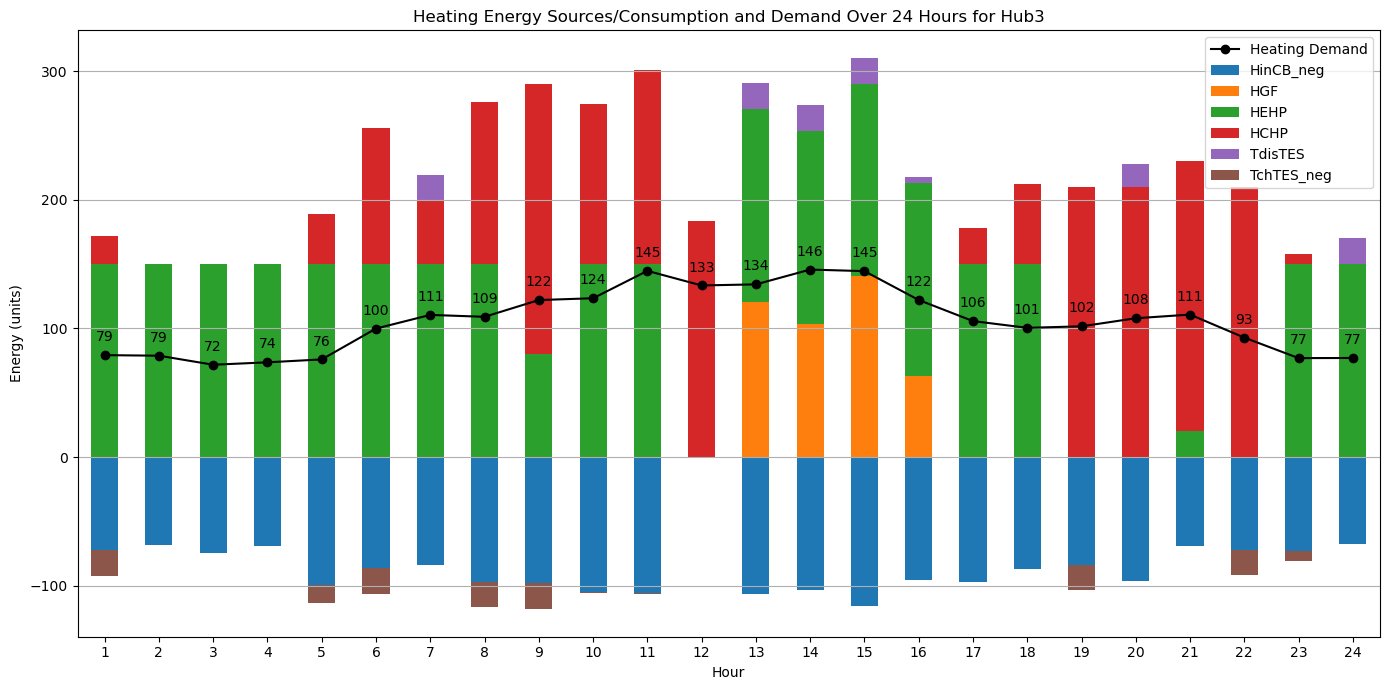

In [12]:
import matplotlib.pyplot as plt
import pandas as pd


# Create a new column with negative values for EinEHP to represent consumption
df_results['TchTES_neg'] = -df_results['TchTES']
df_results['HinCB_neg'] = -df_results['HinCB']

# Select the relevant columns for the stacked bar plot, including the negative values
plot_columns = ['HinCB_neg','HGF','HEHP','HCHP','TdisTES','TchTES_neg']

for h in model.hubs:
    # Filter data for the current hub
    df_hub = df_results.loc[h]

    # Create the stacked bar plot for the current hub
    fig, ax1 = plt.subplots(figsize=(14, 7))
    df_hub[plot_columns].plot(kind='bar', stacked=True, ax=ax1)

    ax1.set_xlabel("Hour")
    ax1.set_ylabel("Energy (units)")
    ax1.set_title(f"Heating Energy Sources/Consumption and Demand Over 24 Hours for {h}")
    ax1.tick_params(axis='x', rotation=0) # Keep x-axis labels horizontal
    ax1.legend(title="Source/Consumption", loc='upper left')
    ax1.grid(axis='y') # Add a horizontal grid for better readability


    # Add the heating demand line on the primary y-axis
    heating_demand = [data_dict[h][t][0] for t in model.t] # Extract heating demand from data_dict
    demand_line, = ax1.plot(range(len(heating_demand)), heating_demand, color='black', marker='o', linestyle='-', label='Heating Demand') # plot_data.index-1 to align with 0-based indexing of plot

    # Combine legends
    handles, labels = ax1.get_legend_handles_labels()
    ax1.legend(handles=handles, loc='upper right') # Add the legend for the heating demand line

    # Add annotations for the heating demand line
    for i, txt in enumerate(heating_demand):
        ax1.annotate(f'{txt:.0f}', (df_hub.index.get_level_values('Time Step')[i] - 1, heating_demand[i]), textcoords="offset points", xytext=(0,10), ha='center')


    plt.tight_layout() # Adjust layout to prevent labels overlapping
    plt.show()

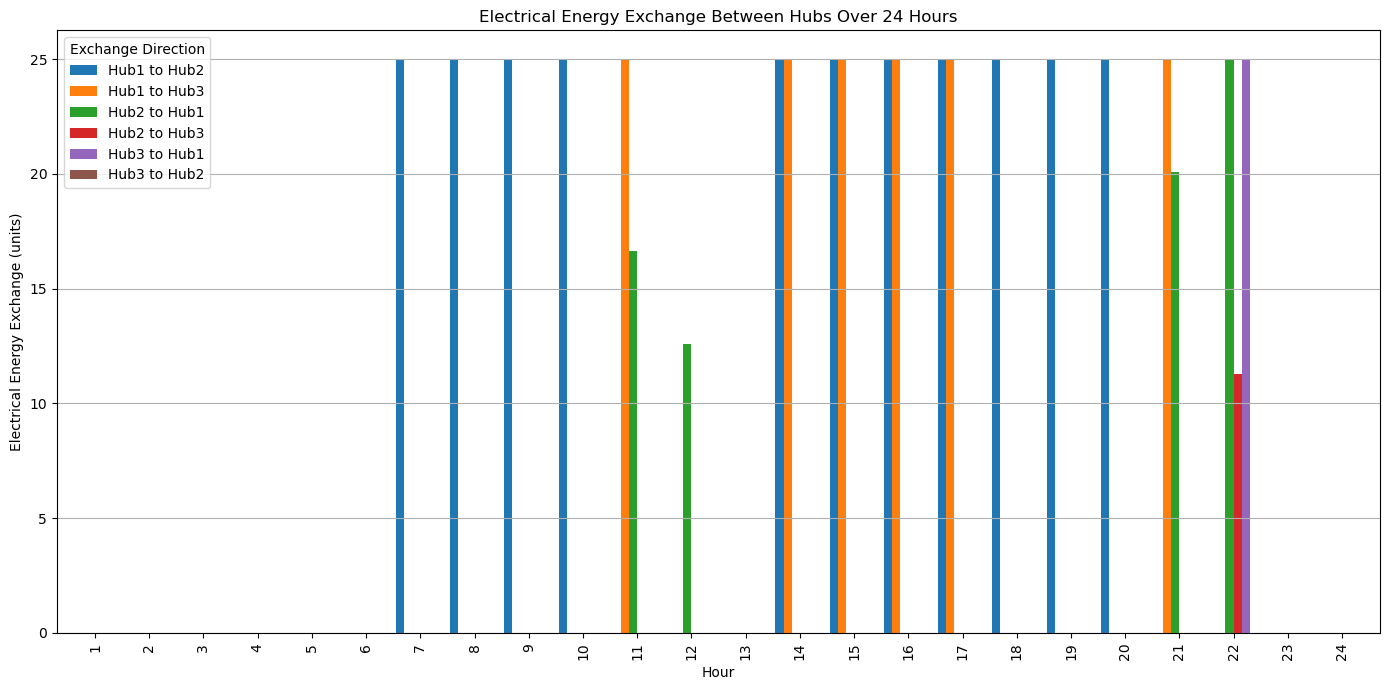

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract the electrical exchange data between hubs
exchange_data = {}
for t in model.t:
    for h1 in model.hubs:
        for h2 in model.hubs:
            if h1 != h2: # Only consider exchange between different hubs
                exchange_data[(h1, h2, t)] = value(model.E_ex[h1, h2, t])

# Convert the exchange data to a pandas DataFrame for easier plotting
df_exchange = pd.DataFrame.from_dict(exchange_data, orient='index', columns=['Electrical Exchange'])

# Set a MultiIndex for the DataFrame
df_exchange.index = pd.MultiIndex.from_tuples(df_exchange.index, names=['From Hub', 'To Hub', 'Time Step'])

# Unstack the DataFrame to have 'Time Step' as the index and exchange directions as columns
df_exchange_unstacked = df_exchange.unstack(level=[0, 1])

# Flatten the multi-level columns for easier plotting
df_exchange_unstacked.columns = [f'{col[1]} to {col[2]}' for col in df_exchange_unstacked.columns]


# Create the plot
fig, ax = plt.subplots(figsize=(14, 7))

df_exchange_unstacked.plot(kind='bar', ax=ax, width=0.9)

ax.set_xlabel("Hour")
ax.set_ylabel("Electrical Energy Exchange (units)")
ax.set_title("Electrical Energy Exchange Between Hubs Over 24 Hours")
ax.set_xticks(df_exchange_unstacked.index - 1) # Set x-ticks to correspond to the hour numbers
ax.set_xticklabels(df_exchange_unstacked.index) # Label x-ticks with hour numbers
ax.grid(axis='y') # Add a horizontal grid for better readability
ax.legend(title="Exchange Direction")

plt.tight_layout()
plt.show()

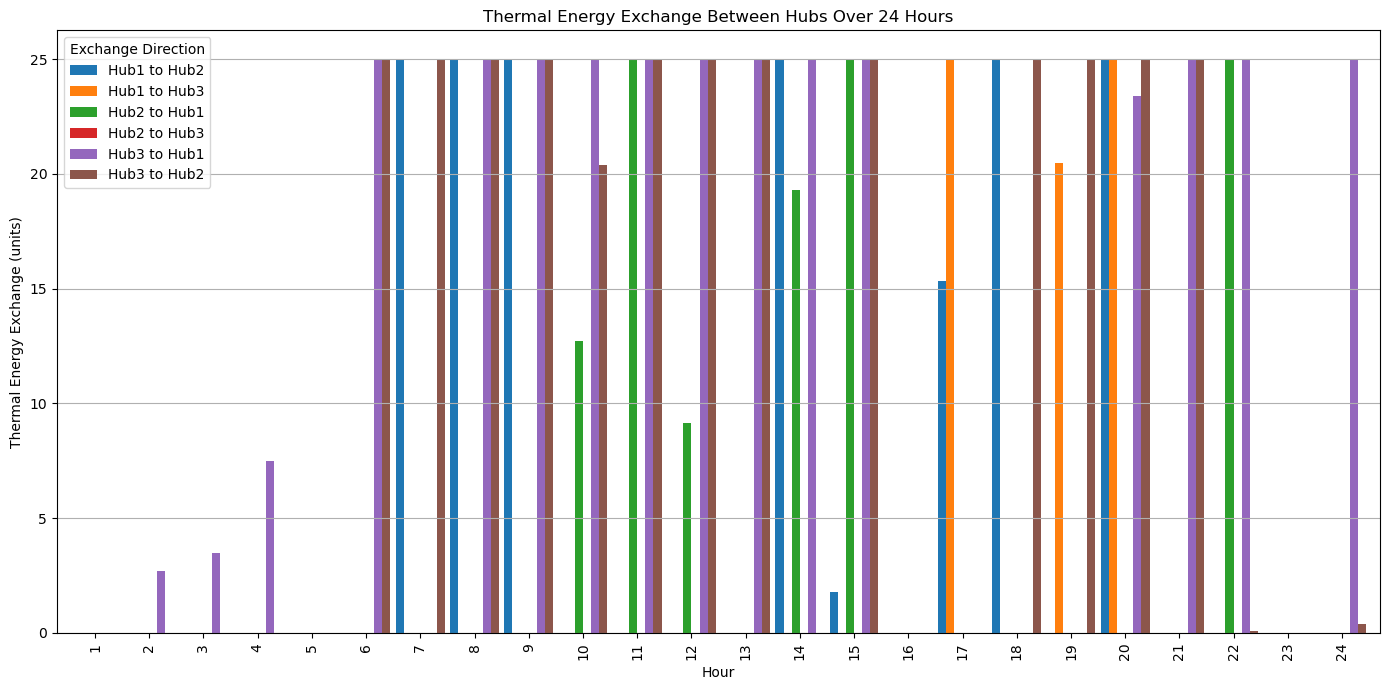

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract the thermal exchange data between hubs
heat_exchange_data = {}
for t in model.t:
    for h1 in model.hubs:
        for h2 in model.hubs:
            if h1 != h2: # Only consider exchange between different hubs
                heat_exchange_data[(h1, h2, t)] = value(model.H_ex[h1, h2, t])

# Convert the exchange data to a pandas DataFrame for easier plotting
df_heat_exchange = pd.DataFrame.from_dict(heat_exchange_data, orient='index', columns=['Thermal Exchange'])

# Set a MultiIndex for the DataFrame
df_heat_exchange.index = pd.MultiIndex.from_tuples(df_heat_exchange.index, names=['From Hub', 'To Hub', 'Time Step'])

# Unstack the DataFrame to have 'Time Step' as the index and exchange directions as columns
df_heat_exchange_unstacked = df_heat_exchange.unstack(level=[0, 1])

# Flatten the multi-level columns for easier plotting
df_heat_exchange_unstacked.columns = [f'{col[1]} to {col[2]}' for col in df_heat_exchange_unstacked.columns]


# Create the plot
fig, ax = plt.subplots(figsize=(14, 7))

df_heat_exchange_unstacked.plot(kind='bar', ax=ax, width=0.9)

ax.set_xlabel("Hour")
ax.set_ylabel("Thermal Energy Exchange (units)")
ax.set_title("Thermal Energy Exchange Between Hubs Over 24 Hours")
ax.set_xticks(df_heat_exchange_unstacked.index - 1) # Set x-ticks to correspond to the hour numbers
ax.set_xticklabels(df_heat_exchange_unstacked.index) # Label x-ticks with hour numbers
ax.grid(axis='y') # Add a horizontal grid for better readability
ax.legend(title="Exchange Direction")

plt.tight_layout()
plt.show()